## 01 - Kaplan Meier Curved and Log Rank Test

- Dataset: `rossi` (lifelines) - 432 people released from prison, followed for 52 weeks.
- Event = re-arrest. Group = financial aid (`fin`)

In [ ]:
!pip install -q matplotlib
!pip install -q lifelines

  Using cached autograd-1.9.1-py3-none-any.whl.metadata (6.1 kB)
  Using cached autograd-gamma-0.5.0.tar.gz (4.0 kB)
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached pytz-2026.6-py2.py3-none-any.whl.metadata (22 kB)
  Using cached tzdata-2026.6-py2.py3-none-any.whl.metadata (1.4 kB)
Using cached autograd-1.9.1-py3-none-any.whl (54 kB)
Using cached formulaic-1.2.2-py3-none-any.whl (118 kB)
Using cached interface_meta-2.0.1-py3-none-any.whl (15 kB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    ----------

  DEPRECATION: Building 'autograd-gamma' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'autograd-gamma'. Discussion can be found at https://github.com/pypa/pip/issues/6334


# 01 - Kaplan Meier curves and the log-rank test

**Goal:** Estimate survival curves from censored data, compare two groups, and test whether they differ.

**Dataset:** rossi from lifelines 432 people released from prison, followed for up to 52 weeks.
- `week` -> follow-up time (weeks)
- `arrest` -> event indicator (1 = re-arrested, 0 = censored)
- `fin` -> received financial aid after release (1 = yes, 0 = no) - the groups we compare


In [17]:
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.datasets import load_rossi
from lifelines.statistics import logrank_test

In [23]:
df = load_rossi()
display(df)

,week,arrest,fin,age,race,wexp,mar,paro,prio
0,20,1,0,27,1,0,0,1,3
1,17,1,0,18,1,0,0,1,8
2,25,1,0,19,0,1,0,1,13
3,52,0,1,23,1,1,1,1,1
4,52,0,0,19,0,1,0,1,3
...,...,...,...,...,...,...,...,...,...
427,52,0,1,31,0,1,0,1,3
428,52,0,0,20,1,0,0,1,1
429,52,0,1,20,1,1,1,1,1
430,52,0,0,29,1,1,0,1,3


The two columns that matter for survival analysis are week (time) and arrest (event).
The other columns (age, prior convictions, etc.) are covariates we'll use in the Cox model.

In [25]:
print(df.shape)

(432, 9)


In [27]:
df.head()

,week,arrest,fin,age,race,wexp,mar,paro,prio
0,20,1,0,27,1,0,0,1,3
1,17,1,0,18,1,0,0,1,8
2,25,1,0,19,0,1,0,1,13
3,52,0,1,23,1,1,1,1,1
4,52,0,0,19,0,1,0,1,3


In [29]:
n_events = df["arrest"].sum()

In [31]:
censored_pct = (df["arrest"] == 0).mean() * 100

In [33]:
print("Events (arrests):", n_events)
print(f"Censored: {censored_pct:.1f}%")
print("Longest follow-up:", df["week"].max(), "weeks")

Events (arrests): 114
Censored: 73.6%
Longest follow-up: 52 weeks


## Kaplan Meier curve for everyone

Steps:
1. `KaplanMeierFitter()` creates an empty KM model.
2. `.fit(durations=..., event_observed=...)` estimates the curve.
   - `durations` = follow-up time for each person
   - `event_observed` = 1 if arrested, 0 if censored
   - `label` = the name shown in the plot legend
3. `.plot_survival_function()` draws the curve.

In [43]:
kmf = KaplanMeierFitter()
kmf.fit(durations=df["week"], event_observed=df["arrest"], label="All")

<lifelines.KaplanMeierFitter:"All", fitted with 432 total observations, 318 right-censored observations>

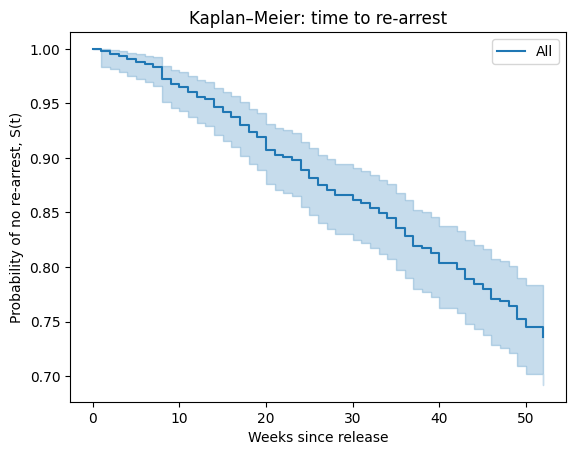

In [45]:
kmf.plot_survival_function()
plt.title("Kaplan–Meier: time to re-arrest")
plt.xlabel("Weeks since release")
plt.ylabel("Probability of no re-arrest, S(t)")
plt.show()

In [47]:
print("Median survival time:", kmf.median_survival_time_)
kmf.survival_function_at_times([10, 26, 52])

Median survival time: inf


10    0.965278
26    0.875000
52    0.736111
Name: All, dtype: float64

### Interpretation
- **Median = inf:** the median is the time when S(t) falls to 0.5. Here S(t) only falls to about
  0.74 by the end of follow-up, so more than half the people were never re-arrested within 52 weeks.
  The median is therefore **not reached**, and lifelines reports it as infinity.

- **S(10) ≈ 0.97, S(26) ≈ 0.88, S(52) ≈ 0.74.**
- **S(52) ≈ 0.74 means:** an estimated 74% of released people are **still not re-arrested one year
  after release**; equivalently, about 26% are re-arrested within the first year.

  
- The curve falls slowly and fairly steadily  the risk of re-arrest is spread across the year rather
  than concentrated at the start (unlike transplant, where risk is highest early).

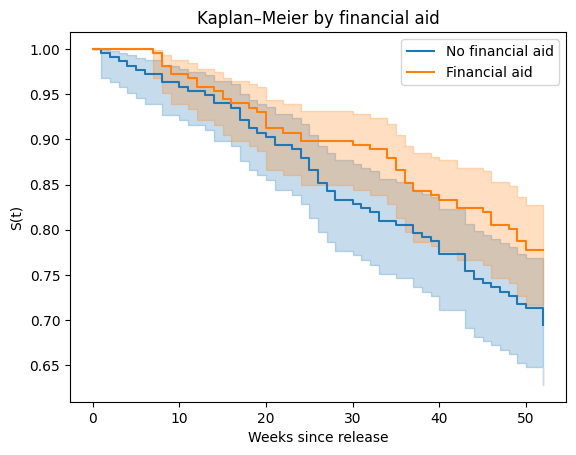

In [49]:
ax = plt.subplot(111)

for group, label in [(0, "No financial aid"), (1, "Financial aid")]:
    mask = df["fin"] == group
    kmf_g = KaplanMeierFitter()
    kmf_g.fit(df.loc[mask, "week"], df.loc[mask, "arrest"], label=label)
    kmf_g.plot_survival_function(ax=ax)

plt.title("Kaplan–Meier by financial aid")
plt.xlabel("Weeks since release")
plt.ylabel("S(t)")
plt.show()

## Log rank test

The plot shows the curves differ, but could that gap just be chance?
The **log-rank test** checks this.

- **Null hypothesis:** both groups have the same survival curve.
- At each event time, it compares the arrests we *observed* in each group with the number we'd *expect* if the groups were the same, then adds this up over all times.
- **Output:** a test statistic and a **p-value**  the probability of seeing a gap this large (or larger) if the groups were truly the same. A small p-value (commonly < 0.05) suggests a real difference.

`logrank_test` takes the times of group A and group B, plus their event flags.
`.print_summary()` prints a neat results table.

Does receiving financial aid help people stay free from arrest for a longer period after being released?

In [64]:
aid = df["fin"] == 1
no_aid = df["fin"] == 0

result = logrank_test(
    df.loc[no_aid, "week"], df.loc[aid, "week"],
    event_observed_A=df.loc[no_aid, "arrest"],
    event_observed_B=df.loc[aid, "arrest"],
)
result.print_summary()

<lifelines.StatisticalResult: logrank_test>
               t_0 = -1
 null_distribution = chi squared
degrees_of_freedom = 1
         test_name = logrank_test

---
 test_statistic    p  -log2(p)
           3.84 0.05      4.32